# INTRODUCTION

Project Objective: Predict next-period churn risk from spend, visits, satisfaction, complaints, tier, and discount use.
EDA Objective: This notebook explores the customer churn dataset. The objective is to identify patterns and factors
associated with customer churn.

### Data Loading

In [5]:
import pandas as pd


In [3]:
df = pd.read_csv("data/raw/synthetic_data_247.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


## Sprint 1: Descriptive Statistics

In [12]:
df.head()

,monthly_spend,number_of_store_visits_per_month,customer_satisfaction_score,number_of_complaints,membership_tier,discount_usage_rate,customer_churn
0,55.23,-0.04460,2.09,0.944,Premium,0.3920,Not Churned
1,158.59,0.00471,4.63,-0.121,Basic,0.4440,Not Churned
2,55.38,1.32000,4.08,-1.100,Premium,0.0549,Not Churned
3,104.11,-1.09000,4.24,-1.030,Premium,0.2740,Not Churned
4,212.91,0.36000,3.63,-0.697,Basic,0.5930,Churned


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   monthly_spend                     1000 non-null   float64
 1   number_of_store_visits_per_month  1000 non-null   float64
 2   customer_satisfaction_score       1000 non-null   float64
 3   number_of_complaints              1000 non-null   float64
 4   membership_tier                   1000 non-null   str    
 5   discount_usage_rate               1000 non-null   float64
 6   customer_churn                    1000 non-null   str    
dtypes: float64(5), str(2)
memory usage: 54.8 KB


In [14]:
df.isnull().sum()

monthly_spend                       0
number_of_store_visits_per_month    0
customer_satisfaction_score         0
number_of_complaints                0
membership_tier                     0
discount_usage_rate                 0
customer_churn                      0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.columns

Index(['monthly_spend', 'number_of_store_visits_per_month',
       'customer_satisfaction_score', 'number_of_complaints',
       'membership_tier', 'discount_usage_rate', 'customer_churn'],
      dtype='str')

In [ ]:
df.shape

(1000, 7)

In [18]:
df.dtypes

monthly_spend                       float64
number_of_store_visits_per_month    float64
customer_satisfaction_score         float64
number_of_complaints                float64
membership_tier                         str
discount_usage_rate                 float64
customer_churn                          str
dtype: object

In [31]:
negative_storev = (df['number_of_store_visits_per_month'] < 0).sum()
negative_complaints = (df['number_of_complaints'] < 0).sum()
positive_storev = (df['number_of_store_visits_per_month'] >= 0).sum()
positive_complaints = (df['number_of_complaints'] >= 0).sum()
print(negative_storev, "negative values in number_of_store_visits_per_month")
print(positive_storev, "non-negative values in number_of_store_visits_per_month")
print(negative_complaints, "negative values in number_of_complaints")
print(positive_complaints, "non-negative values in number_of_complaints")


517 negative values in number_of_store_visits_per_month
483 non-negative values in number_of_store_visits_per_month
515 negative values in number_of_complaints
485 non-negative values in number_of_complaints


In [27]:
df.describe()

,monthly_spend,number_of_store_visits_per_month,customer_satisfaction_score,number_of_complaints,discount_usage_rate
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,90.822380,-0.016246,3.541770,-0.042799,0.280002
std,42.578668,1.016118,0.859725,0.995690,0.155755
min,30.550000,-3.070000,1.140000,-3.160000,0.008100
25%,62.367500,-0.692000,2.940000,-0.723000,0.164000
50%,80.115000,-0.048650,3.650000,-0.038700,0.259500
75%,107.545000,0.614000,4.230000,0.651000,0.389000
max,326.590000,3.270000,4.990000,2.690000,0.837000


In [30]:
df[['number_of_store_visits_per_month', 'number_of_complaints']].describe()

,number_of_store_visits_per_month,number_of_complaints
count,1000.000000,1000.000000
mean,-0.016246,-0.042799
std,1.016118,0.995690
min,-3.070000,-3.160000
25%,-0.692000,-0.723000
50%,-0.048650,-0.038700
75%,0.614000,0.651000
max,3.270000,2.690000


### Initial Data Quality Observations

The initial data exploration identified two numerical 
variables with negative and decimal values:
- number_of_store_visits_per_month
- number_of_complaints

Further investigation revealed:
- 517 negative values (51.7%) in store visits.
- 515 negative values (51.5%) in complaints.
- Both variables have means close to zero.
- Both variables have standard deviations close to one.

These statistical characteristics strongly suggest that 
the two variables have undergone standardisation.

**Preliminary conclusion:** The negative and decimal 
values may be a result of standardisation rather than 
data quality errors. The original transformation process 
has not yet been confirmed.

No data transformations or cleaning have been performed.

In [34]:
membership_tier_counts = (df['membership_tier'].value_counts(normalize=True) * 100).round(2)
customer_churn_counts = (df['customer_churn'].value_counts(normalize=True) * 100).round(2)
print(membership_tier_counts)
print(customer_churn_counts)

membership_tier
Basic      50.0
Premium    30.0
VIP        20.0
Name: proportion, dtype: float64
customer_churn
Not Churned    85.0
Churned        15.0
Name: proportion, dtype: float64


In [36]:
unique_membership_tier = df['membership_tier'].unique()
unique_customer_churn = df['customer_churn'].unique()
print("Unique values in 'membership_tier':", unique_membership_tier)
print("Unique values in 'customer_churn':", unique_customer_churn)

Unique values in 'membership_tier': <StringArray>
['Premium', 'Basic', 'VIP']
Length: 3, dtype: str
Unique values in 'customer_churn': <StringArray>
['Not Churned', 'Churned']
Length: 2, dtype: str


### Categorical Variable Analysis

**1. Membership Tier Distribution**

The dataset consists of three membership tiers: Basic, Premium and VIP.

- Basic: 50% (500 customers)
- Premium: 30% (300 customers)
- VIP: 20% (200 customers)

Basic members represent the largest customer segment, accounting for half of the dataset, while VIP members represent the smallest segment. All three categories are represented in the dataset.

**2. Customer Churn Distribution**

The target variable, `customer_churn`, consists of two categories:

- Not Churned: 85% (850 customers)
- Churned: 15% (150 customers)

The target variable is imbalanced, with non-churned customers significantly outnumbering churned customers.

**Key Observation:**

The class imbalance is an important consideration for subsequent model development. Accuracy alone may not provide a reliable measure of model performance, as a model could achieve 85% accuracy by predicting every customer as not churned. Additional evaluation metrics, such as precision, recall and F1-score, should therefore be considered.

**Data Quality Observation – Membership Tier**

The project brief specifies four membership tiers: Basic, Silver, Gold and Platinum. However, the supplied dataset contains three categories: Basic, Premium and VIP.

As the original data source and category definitions are unavailable for verification, the existing categories will be retained without modification. Subsequent analysis and model development will use the categories as provided in the dataset.

This discrepancy is documented as a limitation of the supplied dataset.

## Sprint 2 – Numerical Feature Distributions and Outlier Analysis.

### Numerical Feature Analysis – Monthly Spend

A histogram is used to examine the distribution of monthly customer spending and identify patterns such as skewness, concentration and potential unusual values.

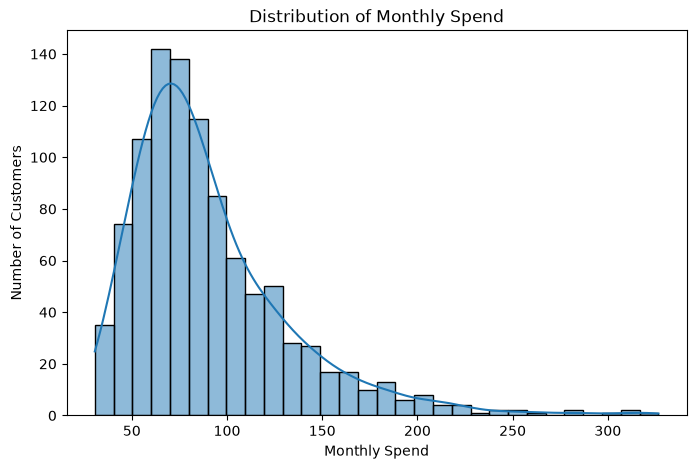

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='monthly_spend', bins=30, kde=True)

plt.title('Distribution of Monthly Spend')
plt.xlabel('Monthly Spend')
plt.ylabel('Number of Customers')

plt.show()

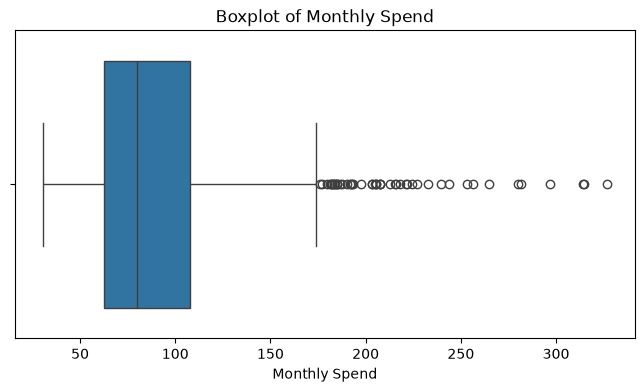

In [38]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x='monthly_spend')

plt.title('Boxplot of Monthly Spend')
plt.xlabel('Monthly Spend')

plt.show()

**Monthly Spend – Outlier Analysis**

The boxplot reveals numerous potential outliers above the upper whisker, with monthly spending values extending to approximately $327. No notable lower-end outliers are observed.

This is consistent with the right-skewed histogram, indicating that a smaller group of customers spends considerably more than the majority.

As the legitimacy of these values cannot be verified due to the absence of additional source information, they will be retained at this stage. Their potential impact on model development will be evaluated during preprocessing and model experimentation.

### Numerical Feature Analysis – Customer Satisfaction Score

A histogram is used to examine the distribution of customer satisfaction score and identify patterns such as skewness, concentration and potential unusual values.

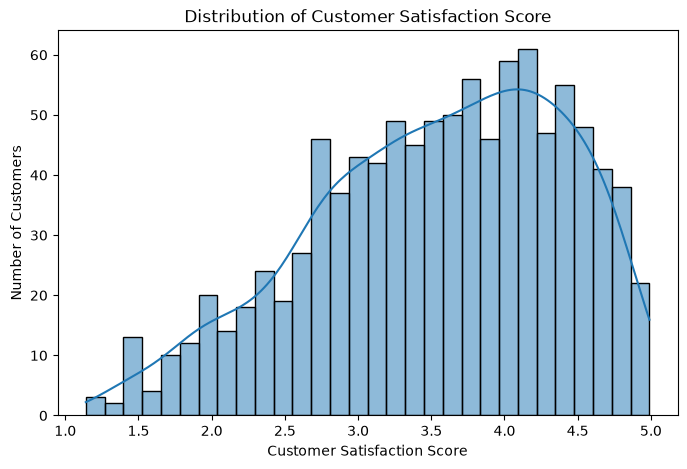

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='customer_satisfaction_score', bins=30, kde=True)

plt.title('Distribution of Customer Satisfaction Score')
plt.xlabel('Customer Satisfaction Score')
plt.ylabel('Number of Customers')

plt.show()

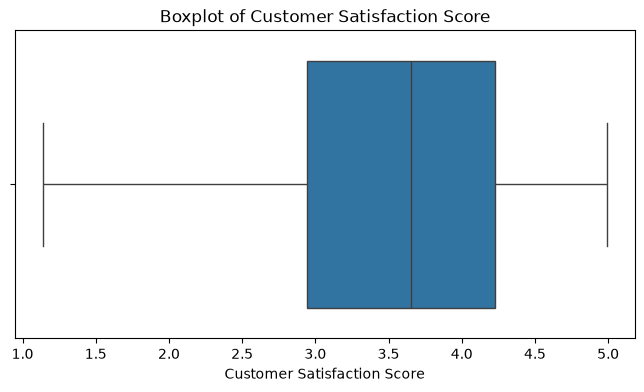

In [43]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x='customer_satisfaction_score')

plt.title('Boxplot of Customer Satisfaction Score')
plt.xlabel('Customer Satisfaction Score')

plt.show()

**Customer Satisfaction Score – Distribution and Outlier Analysis**

The histogram indicates a negatively skewed (left-skewed) distribution, with most customer satisfaction scores concentrated in the middle-to-higher range, approximately between 3.0 and 4.5. Relatively fewer customers report lower satisfaction scores.

The boxplot does not reveal any potential outliers based on the 1.5 × IQR rule. The observed scores range approximately from 1.1 to 5.0.

No data transformations or removals are required at this stage. The original values will be retained for subsequent analysis and model development.

### Numerical Feature Analysis – Number of Store Visits Per Month

A histogram is used to examine the distribution of number of store visits per month and identify patterns such as skewness, concentration and potential unusual values.

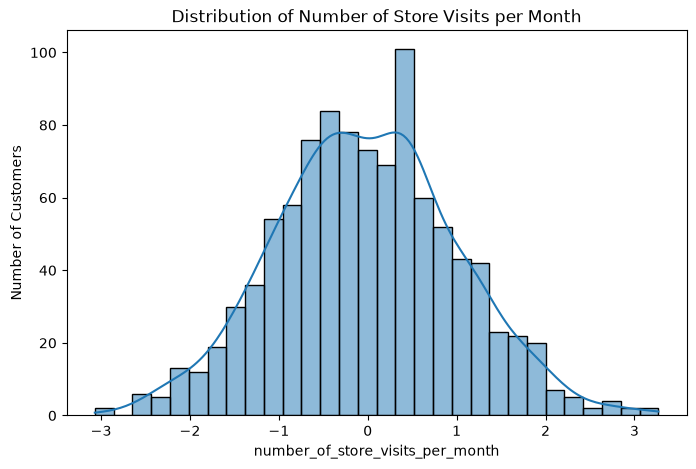

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='number_of_store_visits_per_month', bins=30, kde=True)

plt.title('Distribution of Number of Store Visits per Month')
plt.xlabel('number_of_store_visits_per_month')
plt.ylabel('Number of Customers')

plt.show()

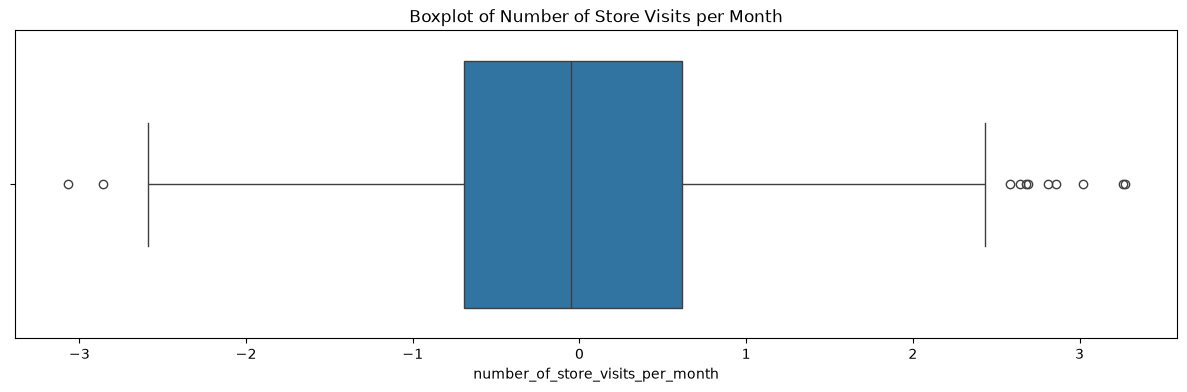

In [47]:
plt.figure(figsize=(15, 4))

sns.boxplot(data=df, x='number_of_store_visits_per_month')

plt.title('Boxplot of Number of Store Visits per Month')
plt.xlabel('number_of_store_visits_per_month')

plt.show()

**Number of Store Visits – Distribution and Outlier Analysis**

The histogram shows an approximately normal, bell-shaped distribution, with most observations concentrated between -1 and +1. The distribution is centred close to zero.

The boxplot identifies potential outliers on both ends of the distribution, with more observations on the upper end than the lower end.

The variable contains negative decimal values, which are not consistent with raw store visit counts. Its mean and standard deviation suggest that the values may have undergone standardisation. However, this cannot be confirmed due to the absence of source transformation information.

The original values will be retained without modification pending further analysis.

### Numerical Feature Analysis – Number of Complaints

A histogram is used to examine the distribution of number of complaints and identify patterns such as skewness, concentration and potential unusual values.

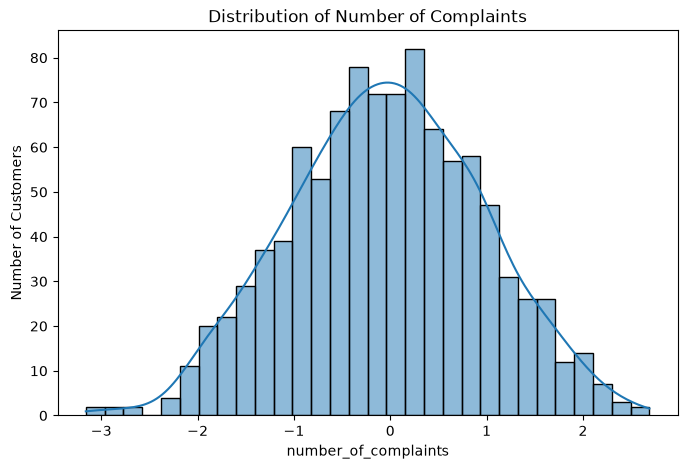

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='number_of_complaints', bins=30, kde=True)

plt.title('Distribution of Number of Complaints')
plt.xlabel('number_of_complaints')
plt.ylabel('Number of Customers')

plt.show()

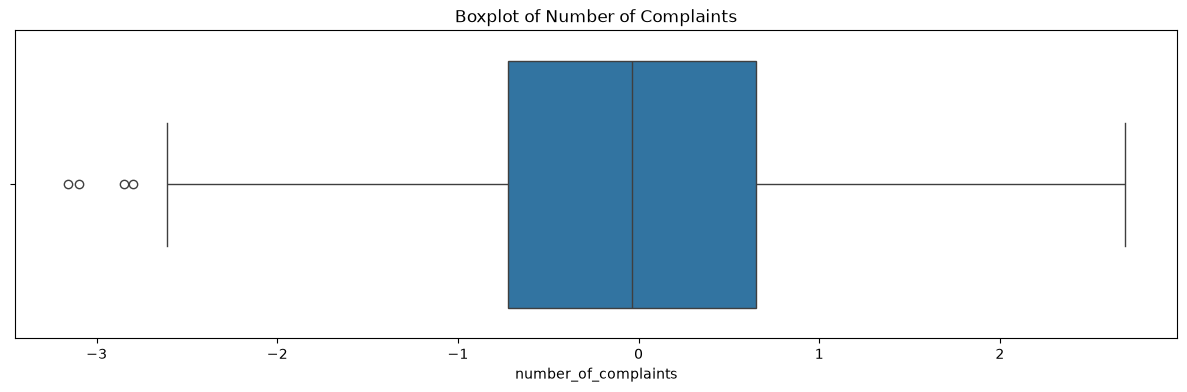

In [51]:
plt.figure(figsize=(15, 4))

sns.boxplot(data=df, x='number_of_complaints')

plt.title('Boxplot of Number of Complaints')
plt.xlabel('number_of_complaints')

plt.show()

**Number of Complaints – Distribution and Outlier Analysis**

The histogram shows an approximately normal, bell-shaped distribution, with most observations concentrated between -1 and +1. The distribution is centred close to zero.

The boxplot identifies approximately four potential outliers on the lower end of the distribution, below -2.5. No potential outliers are observed on the upper end.

Similar to the number of store visits variable, this column contains negative decimal values, which are inconsistent with raw complaint counts. Its distribution, mean and standard deviation suggest that the values may have undergone standardisation. However, this cannot be confirmed due to the absence of source transformation information.

The original values will be retained without modification pending further analysis.

### Numerical Feature Analysis – Discount Usage Rate

A histogram is used to examine the distribution of discount usage rate and identify patterns such as skewness, concentration and potential unusual values.

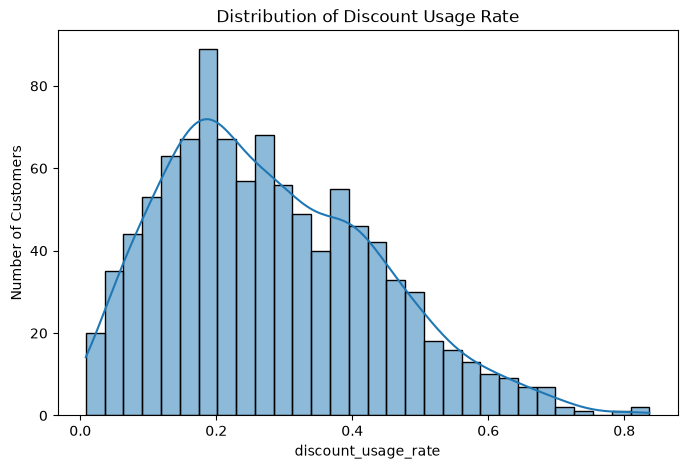

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='discount_usage_rate', bins=30, kde=True)

plt.title('Distribution of Discount Usage Rate')
plt.xlabel('discount_usage_rate')
plt.ylabel('Number of Customers')

plt.show()

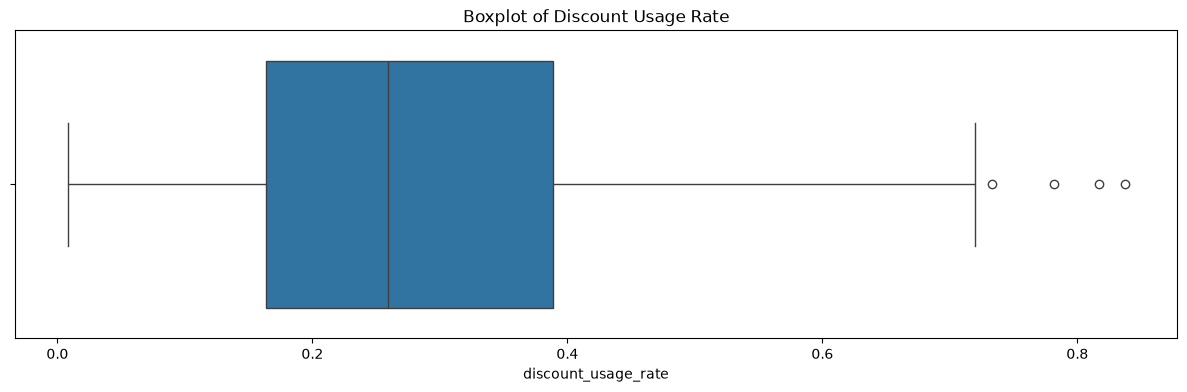

In [55]:
plt.figure(figsize=(15, 4))

sns.boxplot(data=df, x='discount_usage_rate')

plt.title('Boxplot of Discount Usage Rate')
plt.xlabel('discount_usage_rate')

plt.show()

**Discount Usage Rate – Distribution and Outlier Analysis**

The histogram shows a positively skewed (right-skewed) distribution, indicating that most customers have relatively low to moderate discount usage rates, while a smaller proportion use discounts more frequently.

The boxplot shows that the middle 50% of observations are concentrated approximately between 0.18 and 0.40. Approximately four potential outliers are identified on the upper end, above 0.70.

These observations suggest that heavy discount users represent a relatively small proportion of the customer base. The potential outliers will be retained at this stage, as their legitimacy cannot be verified using the available dataset alone.

### Summary – Numerical Feature Distribution and Outlier Analysis

The following table summarises the distribution patterns and potential outliers identified across all five numerical variables.

| Numerical Variable | Distribution | Potential Outliers |
|---|---|---|
| Monthly Spend | Right-skewed | Numerous outliers on the upper end |
| Customer Satisfaction Score | Left-skewed | None identified |
| Number of Store Visits | Approximately normal | Outliers on both ends, more on the upper end |
| Number of Complaints | Approximately normal | Approximately 4 outliers on the lower end |
| Discount Usage Rate | Right-skewed | Approximately 4 outliers on the upper end |

**Key Findings:**

1. Monthly spending and discount usage rate are positively skewed, indicating that a smaller proportion of customers have substantially higher values.
2. Customer satisfaction scores are negatively skewed, suggesting that most customers report moderate-to-high satisfaction.
3. Store visits and number of complaints have approximately normal distributions, with most observations concentrated around the mean.
4. Potential outliers were identified across four of the five numerical variables. Their legitimacy cannot be verified with the available data, so no observations have been removed or modified at this stage.
5. Store visits and complaints contain negative decimal values despite representing count-based variables. Their distributions suggest possible standardisation, although this cannot be confirmed.

**Conclusion:**

The numerical features exhibit different distribution patterns and varying degrees of potential outliers. These findings will inform subsequent data preprocessing decisions. All original values will be retained until further analysis and model experimentation establish whether any transformations are necessary.

### Correlation Analysis

Correlation analysis is conducted to examine the relationships between numerical features and identify potential multicollinearity.

Pearson correlation coefficients are used to measure the strength and direction of linear relationships between numerical variables.

In [56]:
correlation_matrix = df.corr(numeric_only=True)

correlation_matrix

,monthly_spend,number_of_store_visits_per_month,customer_satisfaction_score,number_of_complaints,discount_usage_rate
monthly_spend,1.000000,0.171259,0.150452,-0.104301,0.310310
number_of_store_visits_per_month,0.171259,1.000000,0.079046,0.168678,0.202712
customer_satisfaction_score,0.150452,0.079046,1.000000,-0.588649,0.147731
number_of_complaints,-0.104301,0.168678,-0.588649,1.000000,0.039746
discount_usage_rate,0.310310,0.202712,0.147731,0.039746,1.000000


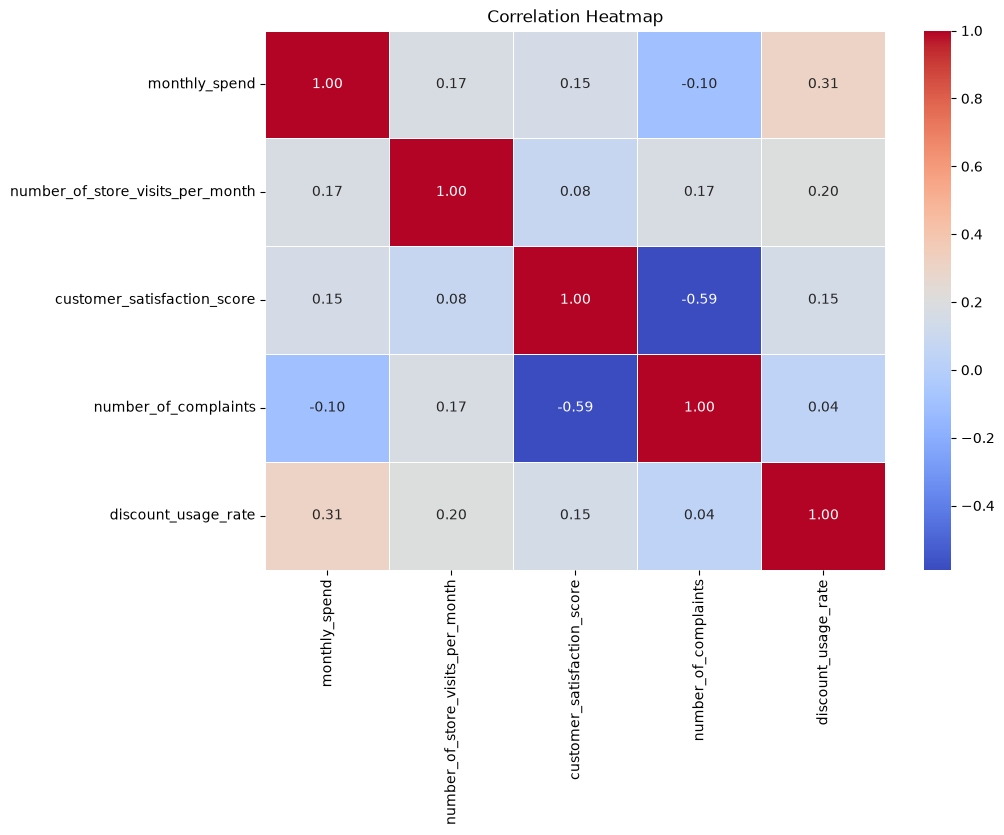

In [58]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
    
plt.title('Correlation Heatmap')

plt.savefig(
    'outputs/figures/correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Correlation Analysis – Findings and Interpretation

Pearson correlation analysis was conducted to examine the relationships between the five numerical features.

**Key Findings:**

1. **Strongest negative relationship:** Customer satisfaction score and number of complaints show a moderate negative correlation (-0.59). This suggests that customers reporting more complaints tend to have lower satisfaction scores.

2. **Strongest positive relationship:** Monthly spend and discount usage rate show a weak-to-moderate positive correlation (+0.31), suggesting that higher spending customers tend to have somewhat higher discount usage rates.

3. **Weak relationships:** Most other numerical feature pairs exhibit very weak correlations, with coefficients relatively close to zero.

**Implications for Model Development:**

- No extremely high correlations (above +0.7 or below -0.7) were identified between numerical features. There is no immediate indication of severe multicollinearity.
- All five numerical features will be retained for subsequent model development, as there is currently insufficient evidence to justify removing any features based on correlation alone.
- Further feature assessment will be conducted during model development.

**Limitation:** Correlation measures linear relationships between numerical variables and does not establish causation or determine how useful a feature is for predicting customer churn.

### Target Variable Analysis – Monthly Spend vs Customer Churn

This analysis compares monthly spending between churned and non-churned customers to investigate whether spending behaviour differs between the two groups.

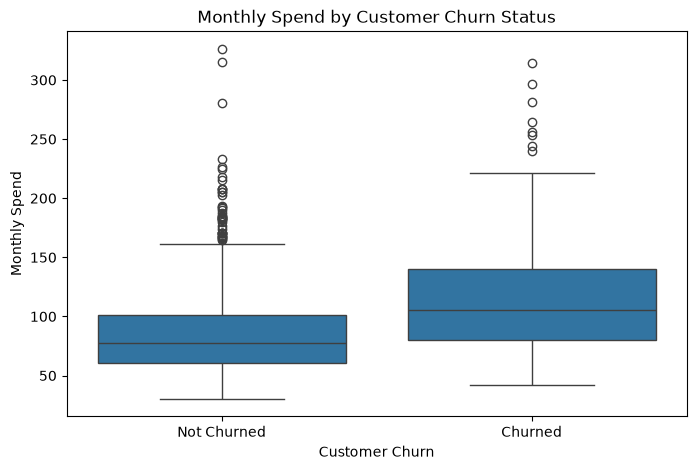

In [59]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='customer_churn',
    y='monthly_spend'
)

plt.title('Monthly Spend by Customer Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Monthly Spend')

plt.savefig(
    'outputs/figures/monthly_spend_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Standardised Store Visits vs Customer Churn

This analysis compares standardised store visit values between churned and non-churned customers to investigate whether differences in relative store visit behaviour are associated with customer churn.

Note: The original store visit counts are unavailable. Therefore, the standardised values are used as provided, and actual visit frequencies cannot be inferred.

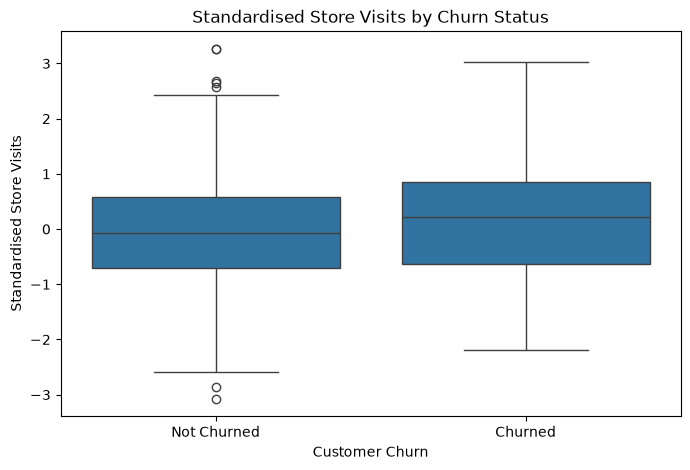

In [60]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='customer_churn',
    y='number_of_store_visits_per_month'
)

plt.title('Standardised Store Visits by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Standardised Store Visits')

plt.savefig(
    'outputs/figures/store_visits_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Standardised Store Visits vs Customer Churn – Findings and Interpretation

The boxplot comparison reveals relatively small differences in standardised store visit values between churned and non-churned customers.

**Key Findings:**

1. **Median:** Churned customers have a slightly higher median standardised visit value compared to non-churned customers, suggesting relatively higher visit activity.
2. **IQR:** The churned group has a slightly wider interquartile range, indicating greater variability in standardised visit values.
3. **Distribution:** Both groups have broadly similar distributions with considerable overlap. The boxplot alone is insufficient to establish whether either distribution is normally distributed or skewed.
4. **Potential Outliers:** Several potential outliers are observed in the non-churned group on both ends of the distribution, while none are identified in the churned group.

**Business Implications:**

The differences between the two groups are relatively small, and standardised store visit values do not appear to provide a strong visual distinction between churned and non-churned customers.

**Conclusion:**

There is no clear evidence from this visualisation that store visit behaviour alone strongly distinguishes customers who churn from those who remain. The feature will be retained for subsequent model development, where its predictive usefulness can be evaluated alongside other customer characteristics.

**Data Limitation:** The original store visit counts are unavailable. Therefore, actual visit frequencies and purchasing patterns cannot be established from the standardised values.

### Monthly Spend vs Standardised Store Visits by Churn Status

This analysis examines the relationship between monthly spending and standardised store visit values, with customers differentiated by churn status.

The objective is to identify whether spending and relative store visit patterns differ between churned and non-churned customers.

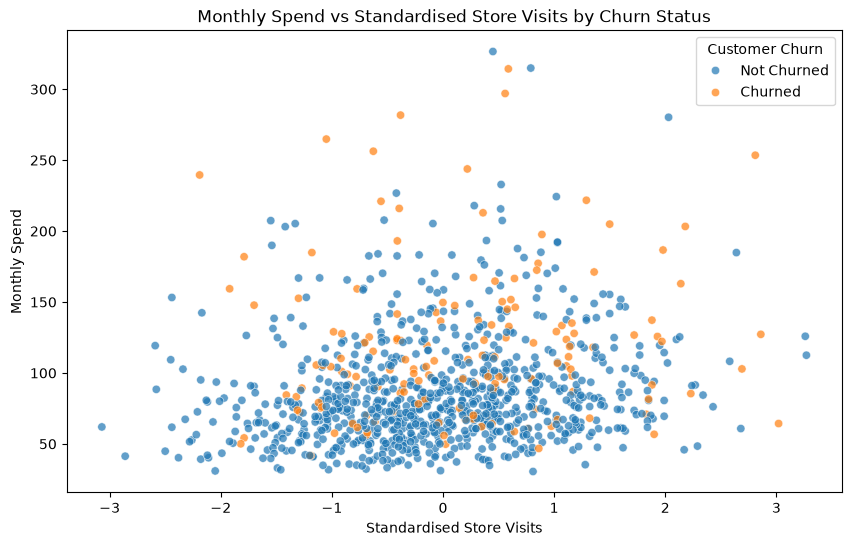

In [61]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='number_of_store_visits_per_month',
    y='monthly_spend',
    hue='customer_churn',
    alpha=0.7
)

plt.title('Monthly Spend vs Standardised Store Visits by Churn Status')
plt.xlabel('Standardised Store Visits')
plt.ylabel('Monthly Spend')
plt.legend(title='Customer Churn')

plt.savefig(
    'outputs/figures/spend_vs_visits_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Monthly Spend vs Standardised Store Visits by Churn Status – Findings and Interpretation

The scatter plot examines the relationship between monthly spending and standardised store visit values, with customers differentiated by churn status.

**Key Findings:**

1. **Relationship between variables:** The Pearson correlation coefficient of +0.17 indicates a very weak positive linear relationship between standardised store visits and monthly spending. The scatter plot also shows considerable variation in spending across different visit values.

2. **Churn distribution:** Churned customers appear to have higher monthly spending values overall, consistent with the earlier boxplot findings.

3. **Higher spending customers:** Several churned customers are observed in the higher spending range, particularly above approximately $220. However, non-churned customers are also present in these ranges.

4. **Group overlap:** Churned and non-churned customers overlap considerably, particularly below $150 in monthly spending. Neither feature appears to clearly distinguish the two customer groups independently.

**Business Implications:**

The presence of higher-spending customers among the churned group suggests potential revenue exposure from customer attrition. However, spending and standardised store visit behaviour alone do not provide a clear distinction between churned and retained customers.

**Conclusion:**

Monthly spending appears to provide a more noticeable visual distinction between churned and non-churned customers than standardised store visit values. However, the substantial overlap between the groups suggests that multiple customer characteristics will need to be considered when developing the churn prediction model.

**Data Limitation:** Standardised store visit values cannot be interpreted as actual visit frequencies. Transaction-level purchasing behaviour and spending per visit cannot be established using the available dataset.

### Standardised Number of Complaints vs Customer Churn

This analysis compares standardised complaint values between churned and non-churned customers to investigate whether differences in relative complaint levels are associated with customer churn.

Note: The original complaint counts are unavailable. Therefore, the standardised values are used as provided, and actual complaint frequencies cannot be inferred.

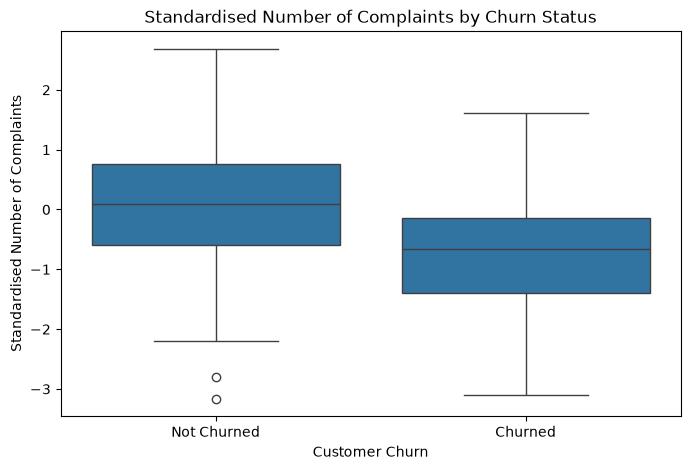

In [62]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='customer_churn',
    y='number_of_complaints'
)

plt.title('Standardised Number of Complaints by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Standardised Number of Complaints')

plt.savefig(
    'outputs/figures/complaints_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Standardised Number of Complaints vs Customer Churn – Findings and Interpretation

The boxplot comparison reveals an unexpected difference in standardised complaint values between churned and non-churned customers.

**Key Findings:**

1. **Median:** Non-churned customers have a higher median standardised complaint value (approximately +0.1) compared to churned customers (approximately -0.7). This suggests that customers who remain have relatively higher complaint values.

2. **IQR:** Both groups have relatively similar interquartile ranges, although the churned group appears to have a slightly narrower spread.

3. **Distribution:** The churned group's distribution is shifted towards lower standardised complaint values compared to the non-churned group.

4. **Potential Outliers:** Approximately two potential outliers are observed below the lower whisker in the non-churned group. No obvious outliers are identified in the churned group.

**Business Implications:**

Contrary to the initial expectation that customers with higher complaint levels may be more likely to churn, the visualisation suggests that non-churned customers have relatively higher complaint values.

This indicates that complaint levels alone may not explain customer churn, and other customer characteristics may play a role.

**Conclusion:**

Standardised complaint values show an unexpected relationship with churn status. Further investigation of customer satisfaction and other behavioural features is required before drawing conclusions about the relationship between complaints and customer retention.

**Data Limitation:** The original complaint counts are unavailable. Therefore, actual complaint frequencies cannot be inferred from the standardised values.

### Monthly Spend vs Standardised Number of Complaints by Churn Status

This analysis examines the relationship between monthly spending and standardised complaint values, with customers differentiated by churn status.

The objective is to investigate whether higher-spending customers who churn exhibit different complaint patterns compared to customers who remain.

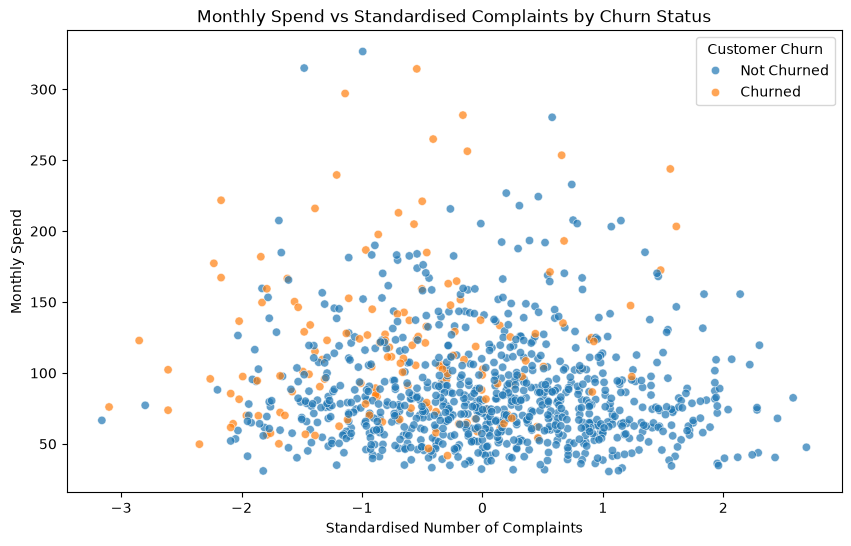

In [63]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='number_of_complaints',
    y='monthly_spend',
    hue='customer_churn',
    alpha=0.7
)

plt.title('Monthly Spend vs Standardised Complaints by Churn Status')
plt.xlabel('Standardised Number of Complaints')
plt.ylabel('Monthly Spend')
plt.legend(title='Customer Churn')

plt.savefig(
    'outputs/figures/spend_vs_complaints_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Monthly Spend vs Standardised Number of Complaints by Churn Status – Findings and Interpretation

The scatter plot examines the relationship between monthly spending and standardised complaint values, with customers differentiated by churn status.

**Key Findings:**

1. **Complaint values among churned customers:** Churned customers appear more concentrated on the negative side of the standardised complaint scale, consistent with the lower median observed in the previous boxplot.

2. **Monthly spending:** Churned customers exhibit a wide range of monthly spending values. Most observations are below approximately $150, although several higher-spending customers are also observed.

3. **Group overlap:** Churned and non-churned customers overlap considerably across both variables. Neither spending nor standardised complaint values appear to clearly distinguish the two groups independently.

**Business Implications:**

The findings suggest that customer churn occurs across different spending levels and that higher complaint values do not necessarily correspond to higher churn in this dataset. The presence of higher-spending customers among those who churn indicates potential revenue exposure.

**Conclusion:**

Monthly spending and standardised complaint values provide some differences between churned and non-churned customers, but considerable overlap remains. Further investigation of customer satisfaction, discount usage and membership tier is required to identify additional patterns associated with churn.

**Data Limitation:** The original complaint counts are unavailable. Negative standardised values represent observations below the dataset average and cannot be interpreted as actual complaint frequencies.

### Customer Satisfaction Score vs Customer Churn

This analysis compares customer satisfaction scores between churned and non-churned customers to investigate whether differences in satisfaction levels are associated with customer churn.

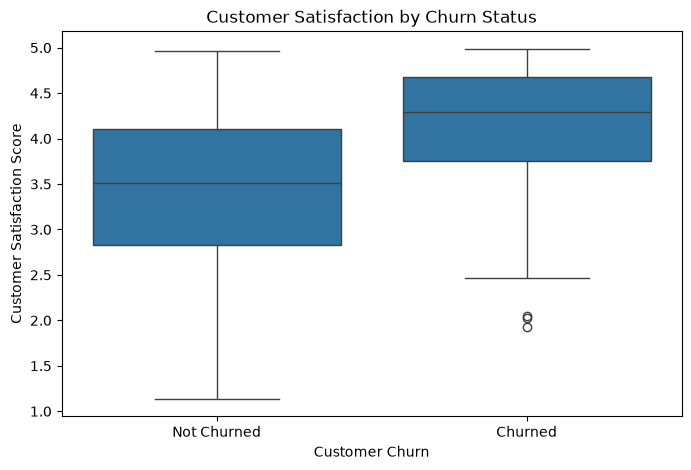

In [64]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='customer_churn',
    y='customer_satisfaction_score'
)

plt.title('Customer Satisfaction by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Customer Satisfaction Score')

plt.savefig(
    'outputs/figures/satisfaction_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Customer Satisfaction Score vs Customer Churn – Findings and Interpretation

The boxplot comparison reveals an unexpected difference in customer satisfaction scores between churned and non-churned customers.

**Key Findings:**

1. **Median:** Churned customers have a higher median satisfaction score (approximately 4.3) compared to non-churned customers (approximately 3.5). This suggests that customers who churn report higher satisfaction scores on average.

2. **IQR:** Non-churned customers have a wider interquartile range, indicating greater variability in satisfaction scores. Churned customers' scores are more concentrated towards the higher end.

3. **Distribution:** The churned group shows a concentration of higher satisfaction scores, while the non-churned group has a wider distribution across the satisfaction scale.

4. **Potential Outliers:** Approximately two potential outliers are observed below the lower whisker in the churned group. No obvious outliers are identified in the non-churned group.

**Business Implications:**

Contrary to the initial expectation that dissatisfied customers may be more likely to churn, the dataset suggests that customers who churn tend to report higher satisfaction scores.

This indicates that satisfaction alone may not explain customer churn, and other customer characteristics or behavioural factors may be involved.

**Conclusion:**

Customer satisfaction shows a noticeable difference between churned and non-churned customers, but the direction of the relationship is unexpected. Further investigation of discount usage and membership tier is required before drawing conclusions about customer churn behaviour.

**Data Limitation:** The observed relationship may reflect characteristics of the supplied synthetic dataset and should not automatically be generalised to real-world retail customers.

### Discount Usage Rate vs Customer Churn

This analysis compares discount usage rates between churned and non-churned customers to investigate whether differences in discount usage behaviour are associated with customer churn.

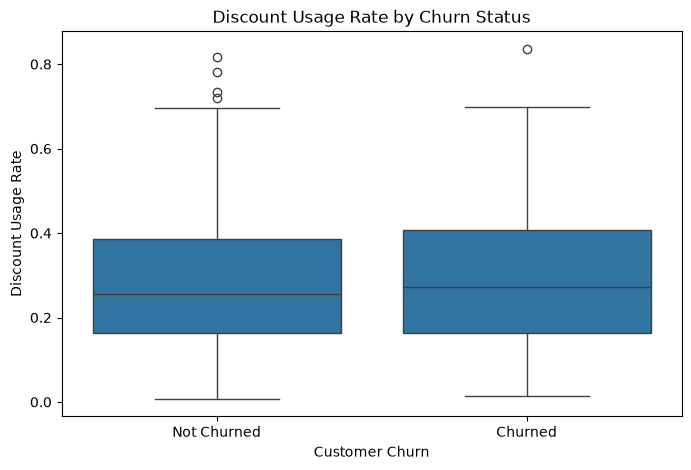

In [65]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='customer_churn',
    y='discount_usage_rate'
)

plt.title('Discount Usage Rate by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Discount Usage Rate')

plt.savefig(
    'outputs/figures/discount_usage_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Discount Usage Rate vs Customer Churn – Findings and Interpretation

The boxplot comparison examines differences in discount usage rates between churned and non-churned customers.

**Key Findings:**

1. **Median:** Churned customers have a slightly higher median discount usage rate (approximately 0.27) compared to non-churned customers (approximately 0.26). However, the difference is minimal.

2. **IQR:** The churned group has a marginally wider interquartile range, indicating slightly greater variability in discount usage rates.

3. **Distribution:** Both groups exhibit broadly similar distributions, with considerable overlap in their discount usage rates.

4. **Potential Outliers:** Approximately four upper-end outliers are observed in the non-churned group, compared to one in the churned group.

**Business Implications:**

Discount usage rates do not appear to provide a strong visual distinction between churned and non-churned customers. Although churned customers have a marginally higher median discount usage rate, the difference is small.

**Conclusion:**

Discount usage alone does not appear to be a strong visual indicator of customer churn. The feature will be retained for subsequent model development, where its predictive usefulness can be evaluated alongside other customer characteristics.

 ### Membership Tier vs Customer Churn

This analysis examines the distribution of churn status across membership tiers to investigate whether customer churn proportions differ between Basic, Premium and VIP members.

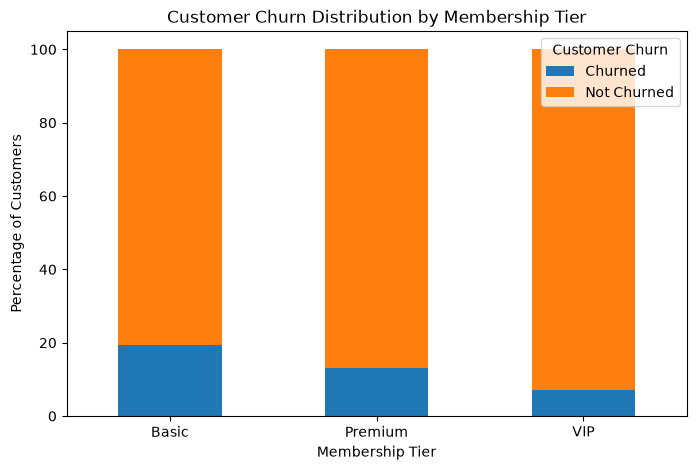

In [68]:
membership_churn = pd.crosstab(
    df['membership_tier'],
    df['customer_churn'],
    normalize='index'
) * 100

membership_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Customer Churn Distribution by Membership Tier')
plt.xlabel('Membership Tier')
plt.ylabel('Percentage of Customers')
plt.legend(title='Customer Churn')
plt.xticks(rotation=0)

plt.savefig(
    'outputs/figures/membership_tier_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Membership Tier vs Customer Churn – Findings and Interpretation

The 100% stacked bar chart compares the proportion of churned and non-churned customers across the three membership tiers.

**Key Findings:**

1. **Basic:** Has the highest churn proportion, at approximately 19.5%.
2. **Premium:** Has a lower churn proportion of approximately 13%.
3. **VIP:** Has the lowest churn proportion, at approximately 7%.

**Business Implications:**

The results suggest an association between membership tier and customer retention. Higher-tier members appear to have lower churn proportions, with VIP members demonstrating the strongest retention.

This may suggest that higher-tier membership benefits or privileges could be associated with improved customer retention. However, further investigation would be required to establish the underlying reasons.

**Conclusion:**

Membership tier appears to provide a noticeable distinction in churn proportions. It may be a useful feature for predicting customer churn and will be retained for subsequent model development.

**Limitation:** These percentages describe the proportion of customers churning within each membership tier. They do not establish that membership tier directly causes or prevents churn.

**Customer Group Sizes:**

The dataset contains 500 Basic members, 300 Premium members and 200 VIP members. The corresponding churn rates are 19.4%, 13.0% and 7.0%, respectively.

The churn rate decreases across the three membership tiers, suggesting an association between higher membership tier and improved customer retention.

In [69]:
pd.crosstab(
    df['membership_tier'],
    df['customer_churn']
)

customer_churn,Churned,Not Churned
membership_tier,,
Basic,97,403
Premium,39,261
VIP,14,186


### Monthly Spend by Membership Tier and Customer Churn

This analysis compares monthly spending across membership tiers, differentiated by customer churn status.

The objective is to investigate whether spending patterns differ across membership tiers and whether the higher median spending observed among churned customers is consistent across all tiers.

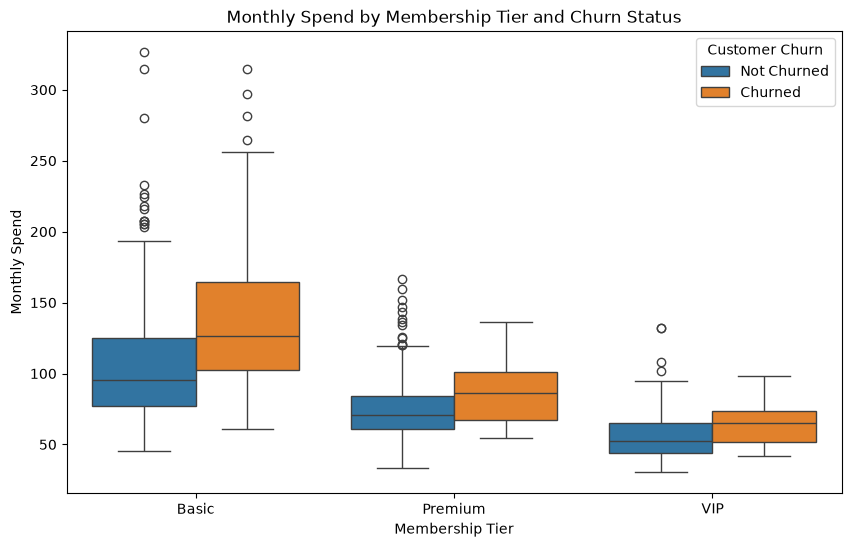

In [70]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='membership_tier',
    y='monthly_spend',
    hue='customer_churn',
    order=['Basic', 'Premium', 'VIP']
)

plt.title('Monthly Spend by Membership Tier and Churn Status')
plt.xlabel('Membership Tier')
plt.ylabel('Monthly Spend')
plt.legend(title='Customer Churn')

plt.savefig(
    'outputs/figures/spend_by_tier_and_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Monthly Spend by Membership Tier and Customer Churn – Findings and Interpretation

The grouped boxplot compares monthly spending between churned and non-churned customers across Basic, Premium and VIP membership tiers.

**Key Findings:**

1. **Spending within membership tiers:** Churned customers have higher median monthly spending than non-churned customers across all three membership tiers.

2. **Basic members:** Churned customers have a median monthly spend of approximately $126, compared to $95 for non-churned customers.

3. **Premium members:** Churned customers have a median monthly spend of approximately $86, compared to $70 for non-churned customers.

4. **VIP members:** Churned customers have a median monthly spend of approximately $64, compared to $52 for non-churned customers.

5. **Spending across membership tiers:** Basic members exhibit higher monthly spending distributions than Premium and VIP members, which is contrary to the initial expectation that higher membership tiers would correspond to higher spending.

**Business Implications:**

The consistently higher median spending among churned customers across all three membership tiers suggests that the observed spending difference is not solely attributable to membership tier composition. This may indicate potential revenue exposure from losing higher-spending customers.

**Conclusion:**

Monthly spending appears to be a potentially useful feature for predicting customer churn. However, the unexpected spending patterns across membership tiers warrant further consideration. The relationship between membership tier and spending cannot be fully explained using the available dataset.

**Data Quality Consideration:** The observed spending patterns are unusual relative to the initial assumption that higher membership tiers correspond to higher spending. However, there is insufficient evidence to conclude that the monthly spending values are incorrect. The original data generation and membership assignment rules are unknown.

In [71]:
churn_by_tier = pd.crosstab(
    df['membership_tier'],
    df['customer_churn'],
    normalize='index'
) * 100

churn_by_tier

customer_churn,Churned,Not Churned
membership_tier,,
Basic,19.4,80.6
Premium,13.0,87.0
VIP,7.0,93.0


## EDA Summary and Key Findings

### 1. Overview

The exploratory data analysis examined the dataset's structure, data quality, numerical distributions, categorical variables, correlations and relationships between customer characteristics and churn status.

The dataset contains 1,000 customer records and 7 features, with 150 customers labelled as Churned (15%) and 850 labelled as Not Churned (85%).

No missing values or duplicate records were identified during the initial data quality assessment.

### 2. Summary of Feature-Level Findings

| Feature | Key Observations | Potential Relevance to Churn |
|---|---|---|
| Monthly spend | Right-skewed distribution with numerous upper-end outliers. Churned customers have higher median spending. | Potentially useful predictor; higher-spending customers may represent greater revenue exposure. |
| Standardised store visits | Approximately normal distribution. Churned customers have a slightly higher median, but substantial overlap exists. | Limited visual differentiation between churn groups. |
| Standardised complaints | Churned customers have a lower median standardised complaint value than non-churned customers. | Unexpected relationship; actual complaint frequencies cannot be established. |
| Customer satisfaction | Churned customers have higher median satisfaction scores and a narrower IQR. | Unexpected relationship that warrants further investigation. |
| Discount usage rate | Churned customers have a marginally higher median, with considerable overlap between groups. | Appears to provide limited visual differentiation between churn groups. |
| Membership tier | Churn rates decrease from Basic (19.4%) to Premium (13.0%) to VIP (7.0%). | Potentially useful predictor of churn. |

### 3. Relationships Between Features

Correlation analysis identified the following relationships:

- Monthly spend and standardised store visits: very weak positive correlation (+0.17).
- Customer satisfaction and standardised complaints: moderate negative correlation (-0.59).
- Monthly spend and discount usage: weak-to-moderate positive correlation (+0.31).

Additional grouped analysis revealed:

- Churned customers have higher median monthly spending across all three membership tiers.
- Basic members have higher monthly spending distributions than Premium and VIP members.
- Churned customers with lower standardised complaint values exhibit a wide range of monthly spending.
- Churned and non-churned customers show considerable overlap across several numerical features.

### 4. Key Business Insights

**Potential revenue exposure**

Churned customers have higher median monthly spending across all membership tiers. This suggests potential revenue exposure from losing higher-spending customers.

**Membership tier and retention**

Basic members have the highest observed churn rate (19.4%), followed by Premium (13.0%) and VIP (7.0%). This suggests an association between membership tier and customer retention.

**Unexpected satisfaction and complaint patterns**

Churned customers have higher median satisfaction scores and lower median standardised complaint values. These observations contradict the initial expectation that dissatisfaction and higher complaint levels would be associated with greater churn.

**Limited individual feature separation**

Several numerical features exhibit considerable overlap between churned and non-churned customers. Combining multiple features may therefore be necessary to develop an effective prediction model.

### 5. Data Quality Concerns and Limitations

**Standardised variables**

The number of store visits and number of complaints contain negative decimal values. Their distributions suggest that they may have been standardised, but the original transformation methodology has not been provided.

Consequently, the values cannot be interpreted as actual visit or complaint counts.

**Unexpected membership and spending patterns**

Basic members exhibit higher spending distributions than Premium and VIP members. This is contrary to the initial expectation that higher membership tiers would correspond to higher spending.

However, the membership assignment criteria are unknown, and there is insufficient evidence to classify these values as incorrect.

**Potential target label inconsistency**

Several feature relationships are unexpected, particularly the higher satisfaction scores and lower standardised complaint values observed among churned customers.

This raises the possibility of unusual synthetic data relationships or potential target-label inconsistencies.

However, the available information does not establish that the Churned and Not Churned labels have been reversed.

The original target definition and assignment methodology remain unknown.

**Synthetic dataset limitations**

The dataset is synthetic. Its observed relationships may not reflect actual retail customer behaviour and should not automatically be generalised to real-world customers.

### 6. Further Investigation and Decisions

Before proceeding to model development, the following investigations are recommended:

1. Conduct statistical tests to assess whether the observed numerical feature differences between churn groups are statistically significant.
2. Conduct a chi-square test to examine the association between membership tier and churn status.
3. Examine effect sizes to assess the practical magnitude of observed differences.
4. Verify the target variable definition and encoding where possible.
5. Retain the original target labels and feature values unless reliable evidence supports a correction.

### 7. EDA Conclusion

The exploratory analysis identified several potentially useful relationships between customer characteristics and churn status, particularly monthly spending and membership tier.

However, some relationships contradict the initial business expectations, and the original definitions of the standardised variables and churn target remain unclear.

The original dataset will be preserved without unsupported modifications. Further statistical investigation and subsequent model evaluation will help determine the predictive usefulness of the available features.

The findings and limitations identified during EDA will inform subsequent preprocessing, feature engineering and model development.

In [72]:
from scipy.stats import mannwhitneyu

churned_spend = df.loc[
    df['customer_churn'] == 'Churned',
    'monthly_spend'
]

not_churned_spend = df.loc[
    df['customer_churn'] == 'Not Churned',
    'monthly_spend'
]

statistic, p_value = mannwhitneyu(
    churned_spend,
    not_churned_spend,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 90126.5
P-value: 6.077922369855582e-16


### Mann–Whitney U Test – Monthly Spending vs Customer Churn

A two-sided Mann–Whitney U test was conducted to determine whether monthly spending distributions differ between churned and non-churned customers.

**Hypotheses:**

- H₀: Monthly spending distributions are the same between churned and non-churned customers.
- H₁: Monthly spending distributions differ between churned and non-churned customers.

**Results:**

- U statistic: 90,126.5
- P-value: 6.08 × 10⁻¹⁶
- Significance level: 0.05

**Interpretation:**

Since the p-value is substantially below 0.05, the null hypothesis is rejected. There is strong statistical evidence of a difference in monthly spending distributions between churned and non-churned customers.

Combined with the earlier boxplot analysis, churned customers exhibit higher median monthly spending.

**Conclusion:**

Monthly spending shows a statistically significant difference between the two churn groups and may be a useful feature for predicting customer churn. However, statistical significance alone does not establish predictive usefulness or causation.

In [73]:
churned_visits = df.loc[
    df['customer_churn'] == 'Churned',
    'number_of_store_visits_per_month'
]

not_churned_visits = df.loc[
    df['customer_churn'] == 'Not Churned',
    'number_of_store_visits_per_month'
]

statistic, p_value = mannwhitneyu(
    churned_visits,
    not_churned_visits,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 70655.5
P-value: 0.03423421870200972


**Statistical Test – Number of Store Visits**

A two-sided Mann–Whitney U test was conducted to compare the distribution of store visits between churned and non-churned customers.

- Mann–Whitney U statistic: 70,655.5
- P-value: 0.0342
- Significance level: 0.05

Since the p-value is below 0.05, the null hypothesis is rejected. There is statistical evidence of a difference in store-visit distributions between the two customer groups.

Based on the earlier boxplot, churned customers appear to have a slightly higher median store-visit value. However, the observed difference should be interpreted cautiously, as the feature appears to contain standardised values rather than actual monthly visit counts.

In [74]:
from scipy.stats import mannwhitneyu

churned_complaints = df.loc[
    df['customer_churn'] == 'Churned',
    'number_of_complaints'
]

not_churned_complaints = df.loc[
    df['customer_churn'] == 'Not Churned',
    'number_of_complaints'
]

statistic, p_value = mannwhitneyu(
    churned_complaints,
    not_churned_complaints,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 35845.5
P-value: 1.1655794485146635e-17


**Statistical Test – Number of Complaints**

A two-sided Mann–Whitney U test was conducted to compare the distribution of complaint values between churned and non-churned customers.

- Mann–Whitney U statistic: 35,845.5
- P-value: 1.17 × 10⁻¹⁷
- Significance level: 0.05

Since the p-value is below 0.05, the null hypothesis is rejected. There is strong statistical evidence of a difference in complaint-value distributions between the two customer groups.

Based on the earlier boxplot, churned customers appear to have lower median complaint values than non-churned customers. However, the feature appears to contain standardised values, and its original scale and interpretation remain uncertain. Therefore, the direction of this relationship should be interpreted cautiously.

In [75]:
churned_satisfaction = df.loc[
    df['customer_churn'] == 'Churned',
    'customer_satisfaction_score'
]

not_churned_satisfaction = df.loc[
    df['customer_churn'] == 'Not Churned',
    'customer_satisfaction_score'
]

statistic, p_value = mannwhitneyu(
    churned_satisfaction,
    not_churned_satisfaction,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 94018.5
P-value: 1.6748548476406814e-20


**Statistical Test – Customer Satisfaction Score**

A two-sided Mann–Whitney U test was conducted to compare customer satisfaction score distributions between churned and non-churned customers.

- Mann–Whitney U statistic: 94,018.5
- P-value: 1.67 × 10⁻²⁰
- Significance level: 0.05

Since the p-value is below 0.05, the null hypothesis is rejected. There is strong statistical evidence of a difference in customer satisfaction score distributions between the two customer groups.

Based on the earlier boxplot, churned customers appear to have higher median satisfaction scores than non-churned customers. This is contrary to conventional expectations, where lower satisfaction would generally be associated with a higher likelihood of churn.

This unexpected relationship should be investigated further. The original churn-label definition and data-generation process are unknown, so the finding should be documented without assuming that the target labels are incorrect.

In [76]:
churned_discount = df.loc[
    df['customer_churn'] == 'Churned',
    'discount_usage_rate'
]

not_churned_discount = df.loc[
    df['customer_churn'] == 'Not Churned',
    'discount_usage_rate'
]

statistic, p_value = mannwhitneyu(
    churned_discount,
    not_churned_discount,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 67695.0
P-value: 0.22646383274074822


**Statistical Test – Discount Usage Rate**

A two-sided Mann–Whitney U test was conducted to compare discount usage rate distributions between churned and non-churned customers.

- Mann–Whitney U statistic: 67,695.0
- P-value: 0.2265
- Significance level: 0.05

Since the p-value is greater than 0.05, we fail to reject the null hypothesis. There is insufficient statistical evidence of a difference in discount usage rate distributions between the two customer groups.

Although the earlier boxplot suggested a slightly higher median discount usage rate among churned customers, this difference was not statistically significant at the 0.05 level.

In [77]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df['membership_tier'],
    df['customer_churn']
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Contingency Table:")
print(contingency_table)

print("\nChi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Contingency Table:
customer_churn   Churned  Not Churned
membership_tier                      
Basic                 97          403
Premium               39          261
VIP                   14          186

Chi-square statistic: 18.57254901960784
P-value: 9.268772506982622e-05
Degrees of freedom: 2


**Statistical Test – Membership Tier and Customer Churn**

A Chi-square test of independence was conducted to investigate whether membership tier is associated with customer churn.

- Chi-square statistic: 18.573
- P-value: 0.0000927
- Degrees of freedom: 2
- Significance level: 0.05

Since the p-value is below 0.05, the null hypothesis is rejected. There is statistically significant evidence of an association between membership tier and customer churn.

The earlier analysis showed that churn rates decrease across membership tiers, from 19.4% for Basic customers to 13.0% for Premium customers and 7.0% for VIP customers.

This suggests that membership tier may be an important factor associated with customer churn. However, statistical association does not establish causation.

In [79]:
%pip install statsmodels

import statsmodels
print(statsmodels.__version__)

168771.04s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


  Using cached statsmodels-0.15.0-cp311-cp311-macosx_10_9_x86_64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.5.2-cp311-cp311-macosx_10_9_x86_64.whl.metadata (7.6 kB)
Using cached statsmodels-0.15.0-cp311-cp311-macosx_10_9_x86_64.whl (11.7 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached wrapt-2.5.2-cp311-cp311-macosx_10_9_x86_64.whl (105 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.
0.15.0


In [1]:
from statsmodels.stats.multitest import multipletests

p_values = [
    6.077922369855582e-16,  # Monthly spend
    0.03423421870200972,    # Store visits
    1.1655794485146635e-17, # Complaints
    1.6748548476406814e-20, # Satisfaction
    0.22646383274074822,    # Discount usage
    9.268772506982622e-05  # Membership tier
]

feature_names = [
    'Monthly spend',
    'Store visits',
    'Complaints',
    'Satisfaction',
    'Discount usage',
    'Membership tier'
]

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method='holm'
)

for feature, original, adjusted, significant in zip(
    feature_names, p_values, p_adjusted, reject
):
    print(
        f"{feature}: Original p-value = {original:.6g}, "
        f"Adjusted p-value = {adjusted:.6g}, "
        f"Significant = {significant}"
    )

Monthly spend: Original p-value = 6.07792e-16, Adjusted p-value = 2.43117e-15, Significant = True
Store visits: Original p-value = 0.0342342, Adjusted p-value = 0.0684684, Significant = False
Complaints: Original p-value = 1.16558e-17, Adjusted p-value = 5.8279e-17, Significant = True
Satisfaction: Original p-value = 1.67485e-20, Adjusted p-value = 1.00491e-19, Significant = True
Discount usage: Original p-value = 0.226464, Adjusted p-value = 0.226464, Significant = False
Membership tier: Original p-value = 9.26877e-05, Adjusted p-value = 0.000278063, Significant = True


### Multiple Testing Correction – Holm Method

Since six statistical tests were conducted, the Holm correction was applied to control the family-wise error rate and reduce the risk of false-positive findings.

The significance level was maintained at 0.05.

**Results after Holm correction:**

| Feature | Original p-value | Adjusted p-value | Significant? |
|---|---:|---:|---|
| Monthly spend | 6.08 × 10⁻¹⁶ | 2.43 × 10⁻¹⁵ | Yes |
| Store visits | 0.0342 | 0.0685 | No |
| Complaints | 1.17 × 10⁻¹⁷ | 5.83 × 10⁻¹⁷ | Yes |
| Satisfaction | 1.67 × 10⁻²⁰ | 1.00 × 10⁻¹⁹ | Yes |
| Discount usage | 0.2265 | 0.2265 | No |
| Membership tier | 0.0000927 | 0.000278 | Yes |

After applying the Holm correction, four out of six features remained statistically significant: monthly spending, number of complaints, customer satisfaction and membership tier.

Store visits was initially statistically significant but no longer met the significance threshold after correction. Discount usage remained statistically insignificant.

These results suggest that monthly spending, complaints, satisfaction and membership tier show evidence of differences or associations with customer churn in this dataset. However, statistical significance alone does not establish predictive importance or causation.

# EDA Summary and Key Findings

## 1. Overview

Exploratory Data Analysis (EDA) was conducted to understand the structure, quality, distributions and relationships within the customer churn dataset.

The dataset contains 1,000 customer records and 7 columns, with no missing values or duplicate records. The target variable, `customer_churn`, contains 150 churned customers (15%) and 850 non-churned customers (85%), indicating class imbalance.

## 2. Key Findings

The following observations were identified:

- **Monthly spending:** Right-skewed distribution with several upper-end outliers. Churned customers generally have higher spending than non-churned customers.
- **Store visits:** Distributions are relatively similar between the two customer groups. The initial statistical result did not remain significant after Holm correction.
- **Number of complaints:** Churned customers appear to have lower median values than non-churned customers.
- **Customer satisfaction:** Churned customers appear to have higher median satisfaction scores, contrary to conventional expectations.
- **Discount usage:** No statistically significant difference was established between churned and non-churned customers.
- **Membership tier:** Churn rates decrease across membership tiers, from Basic (19.4%) to Premium (13.0%) and VIP (7.0%).

## 3. Statistical Testing

Mann–Whitney U tests and a Chi-square test of independence were conducted to investigate relationships between the features and customer churn.

The Holm correction was applied to account for multiple statistical comparisons.

After correction, four features showed statistically significant differences or associations with customer churn:

- Monthly spending
- Number of complaints
- Customer satisfaction
- Membership tier

Store visits and discount usage did not remain statistically significant.

Statistical significance does not establish causation or guarantee predictive usefulness.

## 4. Data Quality Considerations and Limitations

Several observations require further consideration:

- Store visits and complaints contain negative decimal values, suggesting that these features may have been standardised. However, their original scales and transformation processes are unknown.
- Membership tiers in the dataset are Basic, Premium and VIP, which differ from the tiers described in the initial project brief.
- Basic customers have higher average spending than Premium and VIP customers, which may warrant further investigation.
- Churned customers demonstrate higher satisfaction scores and lower complaint values, which are counterintuitive business patterns.
- The dataset is synthetic, and the original data-generation process and churn-label definition are unavailable.

These observations have been documented rather than automatically corrected, as there is insufficient evidence to justify changing the underlying data or target labels.

## 5. Implications for Model Development

Based on the EDA findings, the following considerations will be carried forward:

- Preserve the original churn labels.
- Investigate the unusual values and feature distributions before deciding on preprocessing transformations.
- Encode categorical features appropriately for modelling.
- Account for class imbalance when developing and evaluating models.
- Use stratified data splitting to preserve the churn distribution across training, validation and test sets.
- Evaluate model performance using metrics beyond accuracy, particularly precision, recall, F1-score and ROC-AUC.

## 6. Conclusion

EDA provided an initial understanding of the dataset, highlighted potential data quality concerns and identified several features associated with customer churn.

The findings will guide subsequent data preprocessing, feature engineering and model development. All identified anomalies and limitations will be considered when interpreting the model's results and predictive performance.